<a href="https://colab.research.google.com/github/2403a51078-code/AIDL_LAB_ASSIGNMENTS/blob/main/aidl_lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First 5 rows of dataset:
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  

Dataset Shape:
(1025, 14)

Column Names:
Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     

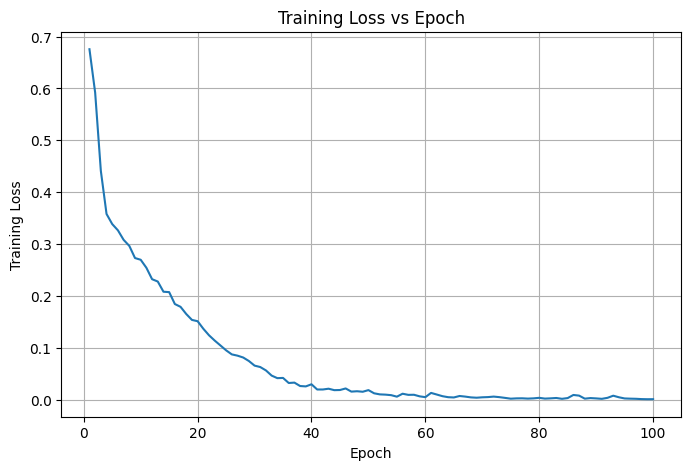


MODEL PERFORMANCE
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1 Score  : 1.0000
ROC-AUC   : 1.0000

Classification Report:
                  precision    recall  f1-score   support

No Heart Disease       1.00      1.00      1.00       100
   Heart Disease       1.00      1.00      1.00       105

        accuracy                           1.00       205
       macro avg       1.00      1.00      1.00       205
    weighted avg       1.00      1.00      1.00       205


Confusion Matrix:
[[100   0]
 [  0 105]]


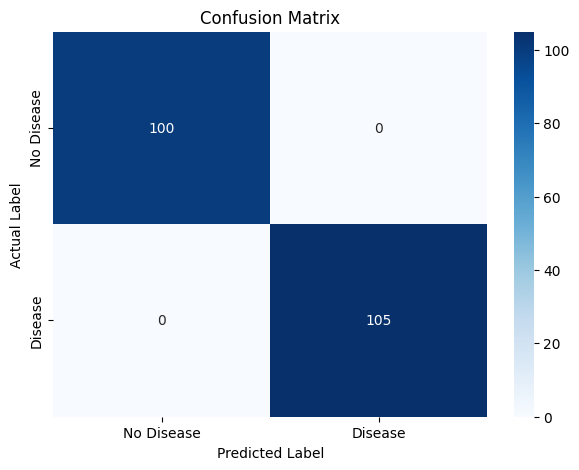

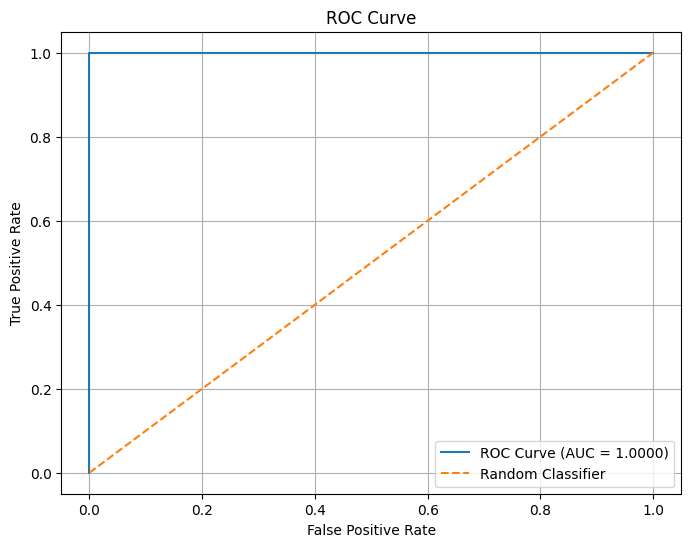


Actual vs Predicted:
    Actual  Predicted
0        0          0
1        1          1
2        0          0
3        1          1
4        0          0
5        0          0
6        1          1
7        0          0
8        1          1
9        1          1
10       0          0
11       1          1
12       0          0
13       0          0
14       1          1
15       0          0
16       0          0
17       0          0
18       0          0
19       1          1

SINGLE PATIENT PREDICTION
Probability of Heart Disease: 99.99%
Prediction: Heart Disease

CONCLUSION

The Heart Disease dataset was successfully loaded and
preprocessed using feature standardization.

A feed-forward neural network was implemented using PyTorch
and trained using the Adam optimizer and Binary
Cross-Entropy loss.

The model was evaluated using Accuracy, Precision, Recall,
F1-score and ROC-AUC.

The confusion matrix shows the number of correctly and
incorrectly classified samples, while the ROC cu

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [ ]:
# ============================================================
# HEART DISEASE PREDICTION USING PYTORCH
# ============================================================

# 1. IMPORT LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

# For reproducibility
torch.manual_seed(42)
np.random.seed(42)


# ============================================================
# 2. LOAD DATASET
# ============================================================

# Dataset uploaded in the notebook/environment
df = pd.read_csv("/content/heart.csv")

print("First 5 rows of dataset:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())


# ============================================================
# 3. PREPROCESS THE DATA
# ============================================================

# Separate input features and target
X = df.drop("target", axis=1)
y = df["target"]

print("\nFeatures:")
print(X.columns)

print("\nTarget distribution:")
print(y.value_counts())


# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


# Standardization
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# Convert NumPy arrays into PyTorch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

y_train_tensor = torch.tensor(
    y_train.values,
    dtype=torch.float32
).reshape(-1, 1)

y_test_tensor = torch.tensor(
    y_test.values,
    dtype=torch.float32
).reshape(-1, 1)


# ============================================================
# 4. CREATE PYTORCH DATASET AND DATALOADER
# ============================================================

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)


# ============================================================
# 5. BUILD THE PYTORCH NEURAL NETWORK
# ============================================================

class HeartDiseaseModel(nn.Module):

    def __init__(self, input_features):
        super(HeartDiseaseModel, self).__init__()

        self.network = nn.Sequential(

            # Input layer -> Hidden layer
            nn.Linear(input_features, 64),
            nn.ReLU(),

            # Hidden layer
            nn.Linear(64, 32),
            nn.ReLU(),

            # Dropout to reduce overfitting
            nn.Dropout(0.2),

            # Hidden layer
            nn.Linear(32, 16),
            nn.ReLU(),

            # Output layer
            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x)


# Number of input features
input_features = X_train.shape[1]

# Create model
model = HeartDiseaseModel(input_features)

print("\nPyTorch Model:")
print(model)


# ============================================================
# 6. DEFINE LOSS FUNCTION AND OPTIMIZER
# ============================================================

# Binary classification
criterion = nn.BCEWithLogitsLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)


# ============================================================
# 7. TRAIN THE MODEL
# ============================================================

epochs = 100

train_losses = []

print("\nStarting Training...\n")

for epoch in range(epochs):

    model.train()

    running_loss = 0.0

    for X_batch, y_batch in train_loader:

        # Forward pass
        outputs = model(X_batch)

        # Calculate loss
        loss = criterion(outputs, y_batch)

        # Clear previous gradients
        optimizer.zero_grad()

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)

    train_losses.append(epoch_loss)

    # Print loss every 10 epochs
    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch + 1}/{epochs}], "
            f"Loss: {epoch_loss:.4f}"
        )


# ============================================================
# 8. PLOT TRAINING LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    train_losses
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss vs Epoch")

plt.grid(True)
plt.show()


# ============================================================
# 9. EVALUATE THE MODEL
# ============================================================

model.eval()

all_probabilities = []
all_predictions = []
all_actual = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        outputs = model(X_batch)

        # Convert logits into probabilities
        probabilities = torch.sigmoid(outputs)

        # Convert probabilities into classes
        predictions = (probabilities >= 0.5).float()

        all_probabilities.extend(
            probabilities.numpy().flatten()
        )

        all_predictions.extend(
            predictions.numpy().flatten()
        )

        all_actual.extend(
            y_batch.numpy().flatten()
        )


# Convert to NumPy arrays
y_pred = np.array(all_predictions).astype(int)
y_probability = np.array(all_probabilities)
y_true = np.array(all_actual).astype(int)


# ============================================================
# 10. CALCULATE PERFORMANCE METRICS
# ============================================================

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_true,
    y_probability
)


print("\n========================================")
print("MODEL PERFORMANCE")
print("========================================")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")


# ============================================================
# 11. CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "No Heart Disease",
            "Heart Disease"
        ],
        zero_division=0
    )
)


# ============================================================
# 12. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

print("\nConfusion Matrix:")
print(cm)


plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Disease",
        "Disease"
    ],
    yticklabels=[
        "No Disease",
        "Disease"
    ]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")

plt.show()


# ============================================================
# 13. ROC CURVE
# ============================================================

fpr, tpr, thresholds = roc_curve(
    y_true,
    y_probability
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ROC Curve (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# 14. ACTUAL VS PREDICTED VALUES
# ============================================================

comparison = pd.DataFrame({
    "Actual": y_true,
    "Predicted": y_pred
})

print("\nActual vs Predicted:")
print(comparison.head(20))


# ============================================================
# 15. TEST A SINGLE PATIENT
# ============================================================

# Example patient:
# age, sex, cp, trestbps, chol, fbs, restecg,
# thalach, exang, oldpeak, slope, ca, thal

patient = np.array([[
    55,     # age
    1,      # sex
    1,      # cp
    140,    # trestbps
    250,    # chol
    0,      # fbs
    1,      # restecg
    150,    # thalach
    0,      # exang
    1.0,    # oldpeak
    1,      # slope
    0,      # ca
    2       # thal
]])

# Scale patient data using the same scaler
patient_scaled = scaler.transform(patient)

# Convert to tensor
patient_tensor = torch.tensor(
    patient_scaled,
    dtype=torch.float32
)

# Prediction
model.eval()

with torch.no_grad():

    output = model(patient_tensor)

    probability = torch.sigmoid(output).item()

    prediction = 1 if probability >= 0.5 else 0


print("\n========================================")
print("SINGLE PATIENT PREDICTION")
print("========================================")

print(
    f"Probability of Heart Disease: "
    f"{probability:.2%}"
)

if prediction == 1:
    print("Prediction: Heart Disease")
else:
    print("Prediction: No Heart Disease")


# ============================================================
# 16. CONCLUSION
# ============================================================

print("\n========================================")
print("CONCLUSION")
print("========================================")

print("""
The Heart Disease dataset was successfully loaded and
preprocessed using feature standardization.

A feed-forward neural network was implemented using PyTorch
and trained using the Adam optimizer and Binary
Cross-Entropy loss.

The model was evaluated using Accuracy, Precision, Recall,
F1-score and ROC-AUC.

The confusion matrix shows the number of correctly and
incorrectly classified samples, while the ROC curve
illustrates the classification performance of the model.

Overall, the PyTorch neural network provides a useful
approach for binary heart disease classification. However,
this model is intended for educational purposes and should
not be used as a medical diagnostic system.
""")